# Analysis of Relational Attention for Transitive Inference
The purpose of this notebook is to analyze the linear relational attention model trained on the pair-wise transitive inference task.

## Imports

In [1]:
import numpy as np
import math
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from relational_attention.tasks import TransitiveInferenceDataset, TransitiveSequenceDataset
from relational_attention.models import RelationalAttentionHead, AttentionClassifier
from relational_attention.training import evaluate_model

In [2]:
torch.manual_seed(42)

## Load model

In [3]:
checkpoint = torch.load("../../data/linear_relational_attention_transitive_inference_full.pt", map_location="cpu")

In [4]:
# Recreate the same architecture
model = AttentionClassifier(
    embed_dim=checkpoint["metadata"]["embed_dim"],
    head_dim=checkpoint["metadata"]["head_dim"],
    attn_cls=RelationalAttentionHead,
    context_size=checkpoint["metadata"]["context_size"],
    linear=True
)
model.load_state_dict(checkpoint["model_state"])
model.eval()

AttentionClassifier(
  (attn): RelationalAttentionHead(
    (W_q): Linear(in_features=5, out_features=5, bias=False)
    (W_k): Linear(in_features=5, out_features=5, bias=False)
  )
  (fc): Linear(in_features=10, out_features=1, bias=True)
)

## Visualize query, key, value matrices

In [5]:
attn_head = model.attn
Q_weights = attn_head.W_q.weight.data
K_weights = attn_head.W_k.weight.data
V_matrix = attn_head.V.data

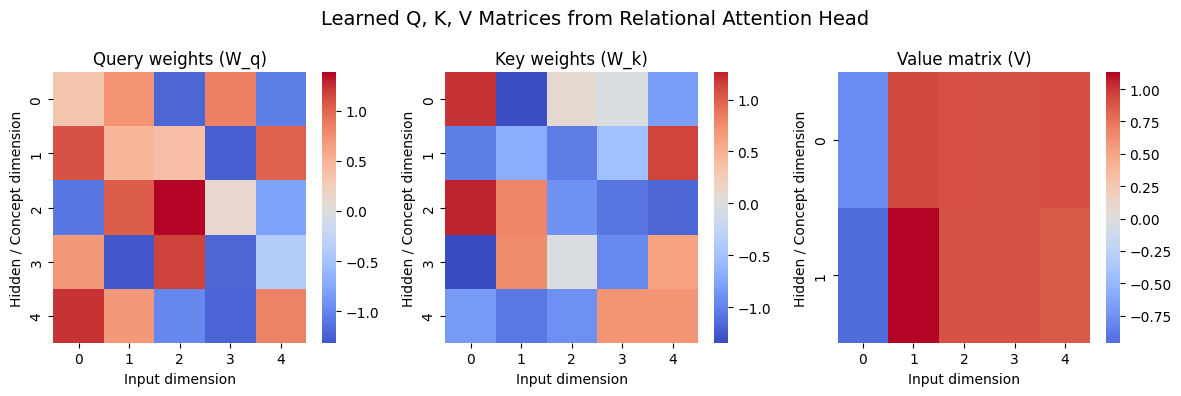

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(Q_weights, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Query weights (W_q)")

sns.heatmap(K_weights, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Key weights (W_k)")

sns.heatmap(V_matrix, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Value matrix (V)")

for ax in axes:
    ax.set_xlabel("Input dimension")
    ax.set_ylabel("Hidden / Concept dimension")

plt.suptitle("Learned Q, K, V Matrices from Relational Attention Head", fontsize=14)
plt.tight_layout()
plt.show()

## Covariance structure of the matrices

In [7]:
def covariance(matrix):
    # subtract mean for proper covariance
    matrix_centered = matrix - matrix.mean(axis=0, keepdims=True)
    return np.cov(matrix_centered.T)  # (D, D)

In [8]:
cov_q = covariance(Q_weights)
cov_k = covariance(K_weights)
cov_v = covariance(V_matrix)

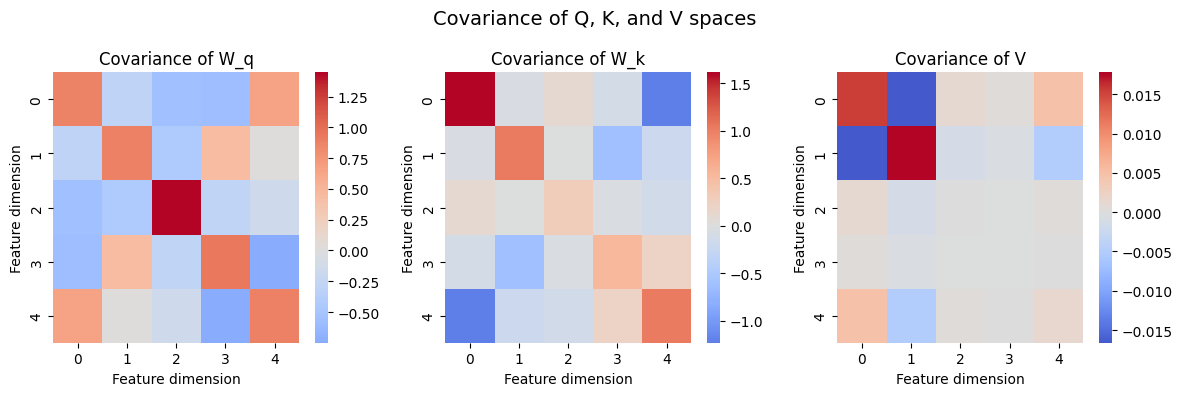

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(cov_q, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Covariance of W_q")

sns.heatmap(cov_k, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Covariance of W_k")

sns.heatmap(cov_v, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Covariance of V")

for ax in axes:
    ax.set_xlabel("Feature dimension")
    ax.set_ylabel("Feature dimension")

plt.suptitle("Covariance of Q, K, and V spaces", fontsize=14)
plt.tight_layout()
# plt.savefig('../results/relational_attention_covariance_transitive_inference.png')
plt.show()

## Geometric interpretation

### Construct task

In [10]:
# Parameters
num_samples = 1000
num_items = 5

In [11]:
# Testing task
dataset_test = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items, train=False)
loader_test = DataLoader(dataset_test, batch_size=16, shuffle=True)

In [12]:
dataset_test.data[0], dataset_test.labels[0]

(tensor([[1., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1.]]),
 tensor(1.))

In [13]:
dataset_test.data[2], dataset_test.labels[2]

(tensor([[0., 0., 0., 0., 1.],
         [0., 0., 1., 0., 0.]]),
 tensor(0.))

In [14]:
acc_linear_relat = evaluate_model(model, loader_test)
print("Linear Relational attention:", acc_linear_relat)

Linear Relational attention: 1.0


### Understand how task input indexes query and keys

In [15]:
model.attn.W_q(dataset_test.data[0])

tensor([[ 0.3356,  1.0977, -1.0968,  0.6965,  1.2357],
        [-1.0420,  1.0234, -0.7916, -0.3762,  0.8272]], grad_fn=<MmBackward0>)

In [16]:
model.attn.W_k(dataset_test.data[0])

tensor([[ 1.2106, -1.0157,  1.2619, -1.3406, -0.8239],
        [-0.8007,  1.1358, -1.1779,  0.6063,  0.7037]], grad_fn=<MmBackward0>)

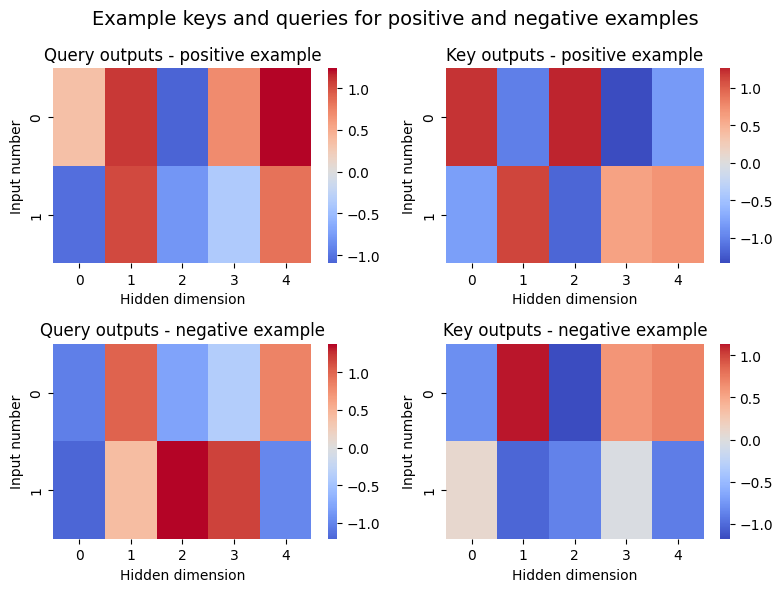

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
sns.heatmap(model.attn.W_q(dataset_test.data[0]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0,0])
axes[0,0].set_title("Query outputs - positive example")

sns.heatmap(model.attn.W_k(dataset_test.data[0]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0,1])
axes[0,1].set_title("Key outputs - positive example")

sns.heatmap(model.attn.W_q(dataset_test.data[2]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[1,0])
axes[1,0].set_title("Query outputs - negative example")

sns.heatmap(model.attn.W_k(dataset_test.data[2]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[1,1])
axes[1,1].set_title("Key outputs - negative example")

for ax_ in axes:
    for ax in ax_:
        ax.set_xlabel("Hidden dimension")
        ax.set_ylabel("Input number")

plt.suptitle("Example keys and queries for positive and negative examples", fontsize=14)
plt.tight_layout()
plt.show()

### Understand how attention weights are created

In [18]:
Q = model.attn.W_q(dataset_test.data[0])
K = model.attn.W_k(dataset_test.data[0])
attn_weights_pos = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
attn_weights_pos.shape

torch.Size([2, 2])

In [19]:
Q = model.attn.W_q(dataset_test.data[2])
K = model.attn.W_k(dataset_test.data[2])
attn_weights_neg = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
attn_weights_neg.shape

torch.Size([2, 2])

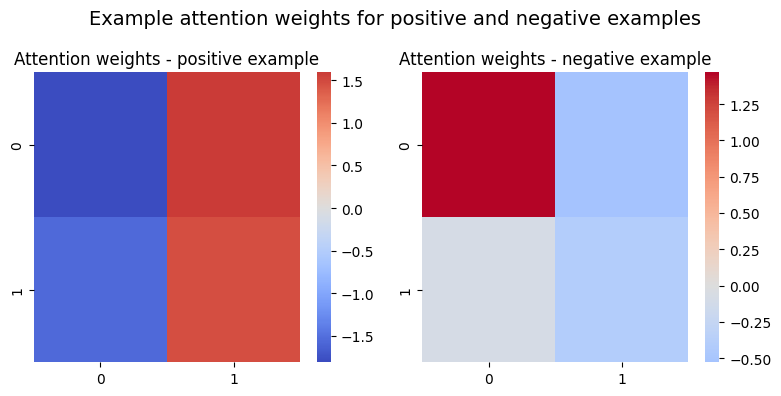

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(attn_weights_pos.detach().numpy(), cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Attention weights - positive example")

sns.heatmap(attn_weights_neg.detach().numpy(), cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Attention weights - negative example")

plt.suptitle("Example attention weights for positive and negative examples", fontsize=14)
plt.tight_layout()
plt.show()

### Visualize how attention weights index on to values

In [21]:
out_positive = attn_weights_pos@V_matrix
out_positive.shape

torch.Size([2, 5])

In [22]:
out_negative = attn_weights_neg@V_matrix
out_negative.shape

torch.Size([2, 5])

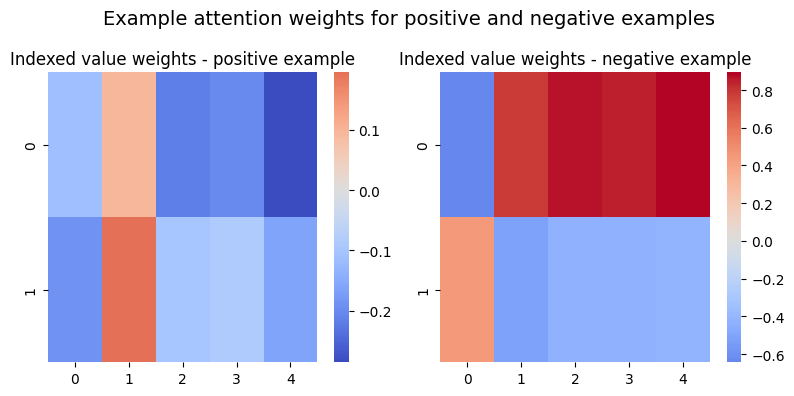

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(out_positive.detach().numpy(), cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Indexed value weights - positive example")

sns.heatmap(out_negative.detach().numpy(), cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Indexed value weights - negative example")

plt.suptitle("Example attention weights for positive and negative examples", fontsize=14)
plt.tight_layout()
plt.show()

## Taking a peak at the attention weights

In [24]:
@torch.no_grad()
def get_attention_weights(model, x):
    """
    x: single example, shape (seq_len, embed_dim)
    returns: attention weights, shape (seq_len, seq_len)
    """
    # Add batch dim if needed
    if x.dim() == 2:
        x = x.unsqueeze(0)  # (1, L, D)

    Q = model.attn.W_q(x)   # (1, L, D_h)
    K = model.attn.W_k(x)   # (1, L, D_h)

    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(K.size(-1))  # (1, L, L)
    weights = torch.softmax(scores, dim=-1)  # (1, L, L)

    return weights.squeeze(0).cpu().numpy()  # (L, L)

In [25]:
# Collect indices for each class
pos_indices = [i for i, y in enumerate(dataset_test.labels) if y == 1]
neg_indices = [i for i, y in enumerate(dataset_test.labels) if y == 0]

# How many of each to visualize
n_show = 5  # e.g. 5 positive + 5 negative

pos_indices = pos_indices[:n_show]
neg_indices = neg_indices[:n_show]

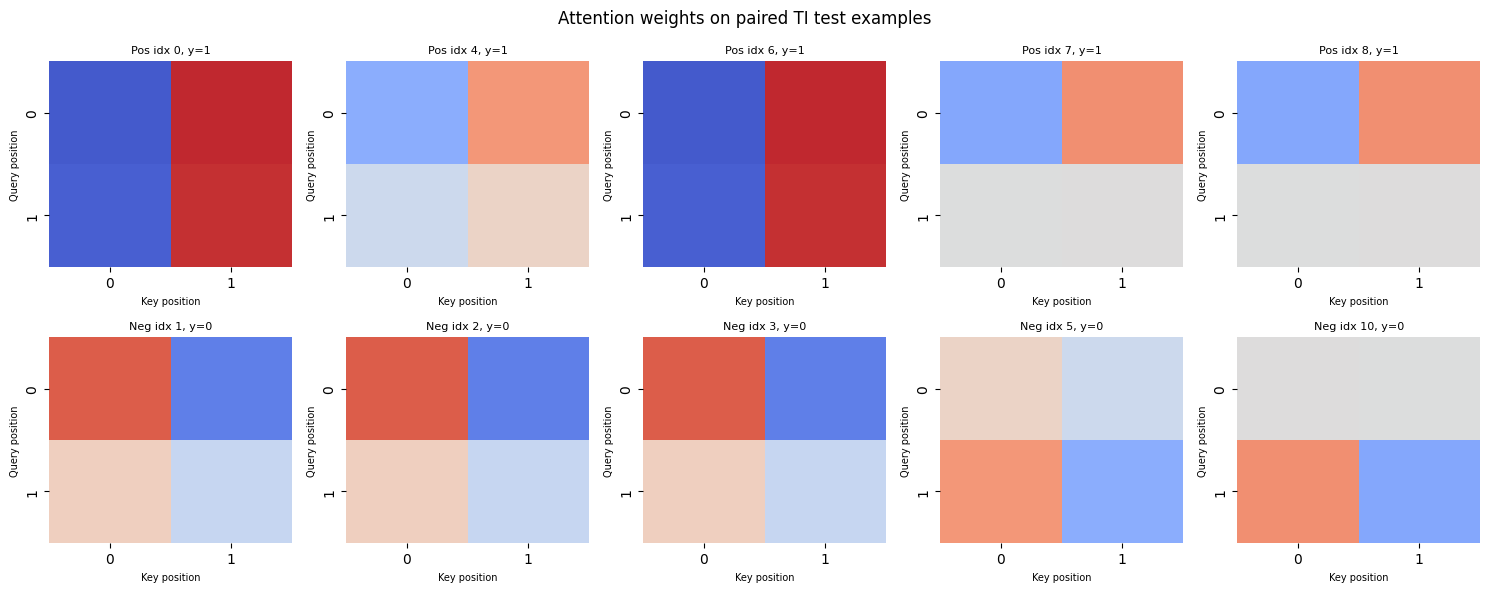

In [26]:
fig, axes = plt.subplots(2, n_show, figsize=(3*n_show, 6))

for col, idx in enumerate(pos_indices):
    x = dataset_test.data[idx]
    y = dataset_test.labels[idx]
    attn = get_attention_weights(model, x)

    ax = axes[0, col]
    sns.heatmap(attn, cmap="coolwarm", center=0.5, vmin=0.0, vmax=1.0,
                cbar=False, ax=ax)
    ax.set_title(f"Pos idx {idx}, y={int(y)}", fontsize=8)
    ax.set_xlabel("Key position", fontsize=7)
    ax.set_ylabel("Query position", fontsize=7)

for col, idx in enumerate(neg_indices):
    x = dataset_test.data[idx]
    y = dataset_test.labels[idx]
    attn = get_attention_weights(model, x)

    ax = axes[1, col]
    sns.heatmap(attn, cmap="coolwarm", center=0.5, vmin=0.0, vmax=1.0,
                cbar=False, ax=ax)
    ax.set_title(f"Neg idx {idx}, y={int(y)}", fontsize=8)
    ax.set_xlabel("Key position", fontsize=7)
    ax.set_ylabel("Query position", fontsize=7)

fig.suptitle("Attention weights on paired TI test examples", fontsize=12)
plt.tight_layout()
plt.show()